In [6]:
#Cluster Analysis
#Bins of Weather, Rides, Histogram and Box Plots
import pandas as pd
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

In [4]:
df=pd.read_csv("C:/Users/gutti/Downloads/divvy_daily_merged.csv")
df

,date,rides,member,casual,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,snowfall,...,cloud_cover,temp_max,temp_min,apparent_max,hours_observed,dow,dow_name,month,is_weekend,precip_any
0,2025-01-01,3562,2321,1241,29.675000,19.570833,68.916667,0.004,0.000,0.028,...,91.750000,33.4,26.5,25.8,24,2,Wednesday,1,False,False
1,2025-01-02,4749,3807,942,27.666667,18.633333,63.416667,0.008,0.000,0.056,...,83.250000,31.5,24.5,22.9,24,3,Thursday,1,False,False
2,2025-01-03,4200,3436,764,22.833333,12.141667,55.375000,0.000,0.000,0.000,...,25.833333,26.0,18.7,16.8,24,4,Friday,1,False,False
3,2025-01-04,3198,2479,719,17.666667,7.712500,48.666667,0.000,0.000,0.000,...,35.708333,22.8,12.3,13.0,24,5,Saturday,1,True,False
4,2025-01-05,2933,2370,563,20.533333,11.058333,57.125000,0.024,0.004,0.138,...,99.416667,27.9,15.8,18.0,24,6,Sunday,1,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2025-12-27,4197,2822,1375,39.754167,34.129167,90.541667,0.008,0.008,0.000,...,99.583333,44.2,37.6,38.8,24,5,Saturday,12,True,False
361,2025-12-28,1997,1481,516,46.116667,41.133333,94.958333,1.623,1.615,0.056,...,100.000000,52.4,26.4,50.1,24,6,Sunday,12,True,True
362,2025-12-29,2388,1995,393,20.329167,7.570833,73.708333,0.084,0.000,0.580,...,99.250000,24.9,16.5,12.5,24,0,Monday,12,False,True
363,2025-12-30,3071,2530,541,17.562500,8.062500,77.833333,0.100,0.000,0.691,...,79.125000,25.2,11.6,17.0,24,1,Tuesday,12,False,True


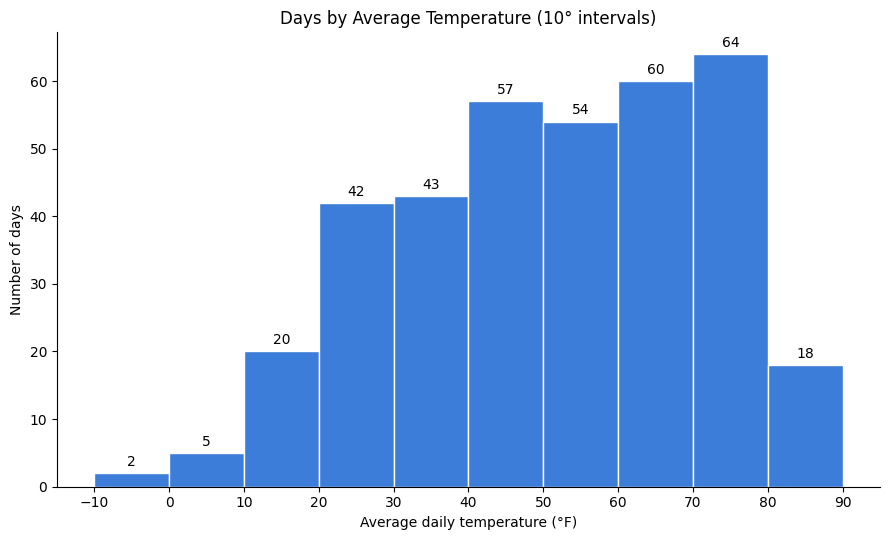

In [ ]:

temps = df["temperature_2m"]  # average daily temperature (°F)
lo = int(np.floor(temps.min() / 10) * 10)
hi = int(np.floor(temps.max() / 10) * 10) + 10
bins = np.arange(lo, hi + 10, 10)
fig, ax = plt.subplots(figsize=(9, 5.5))
counts, edges, patches = ax.hist(temps, bins=bins, color="#3b7dd8", edgecolor="white")
ax.bar_label(patches, padding=3)
ax.set_xticks(bins)
ax.set_xlabel("Average daily temperature (°F)")
ax.set_ylabel("Number of days")
ax.set_title("Days by Average Temperature (10° intervals)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

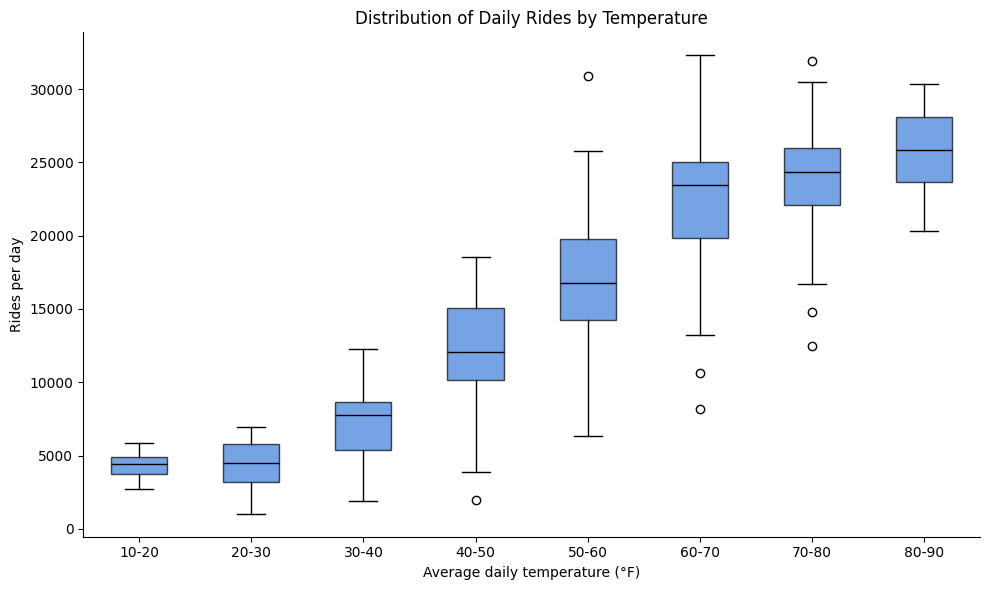

In [ ]:
df = pd.read_csv("divvy_daily_merged.csv")
hi = int(np.floor(df["temperature_2m"].max() / 10) * 10) + 10
bins = np.arange(10, hi + 10, 10)
labels = [f"{b}-{b+10}" for b in bins[:-1]]

df["temp_bin"] = pd.cut(df["temperature_2m"], bins=bins, labels=labels, right=False)
sub = df.dropna(subset=["temp_bin"])
groups = [sub.loc[sub["temp_bin"] == lab, "rides"] for lab in labels]
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(groups, tick_labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
           medianprops=dict(color="black"))
ax.set_xlabel("Average daily temperature (°F)")
ax.set_ylabel("Rides per day")
ax.set_title("Distribution of Daily Rides by Temperature")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
hi = int(np.floor(df["temperature_2m"].max() / 10) * 10) + 10
bins = np.arange(10, hi + 10, 10)
labels = [f"{b}-{b+10}" for b in bins[:-1]]
df["temp_bin"] = pd.cut(df["temperature_2m"], bins=bins, labels=labels, right=False)
sub = df.dropna(subset=["temp_bin"])
def find_outliers(g):
    q1, q3 = g["rides"].quantile([0.25, 0.75])
    iqr = q3 - q1
    return g[(g["rides"] < q1 - 1.5 * iqr) | (g["rides"] > q3 + 1.5 * iqr)]
outliers = (
    sub.groupby("temp_bin", observed=True, group_keys=False)
       .apply(find_outliers)
       [["date", "temp_bin", "temperature_2m", "rides", "dow_name", "precip_any"]]
       .sort_values(["temp_bin", "date"])
)
outliers

C:\Users\gutti\AppData\Local\Temp\ipykernel_6880\637572193.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(find_outliers)


,date,temp_bin,temperature_2m,rides,dow_name,precip_any
361,2025-12-28,40-50,46.116667,1997,Sunday,True
284,2025-10-12,50-60,57.837500,30910,Sunday,False
88,2025-03-30,60-70,60.241667,8194,Sunday,True
154,2025-06-04,60-70,61.541667,10603,Wednesday,True
168,2025-06-18,70-80,71.120833,12459,Wednesday,True
178,2025-06-28,70-80,73.137500,31913,Saturday,False
223,2025-08-12,70-80,75.466667,14777,Tuesday,True


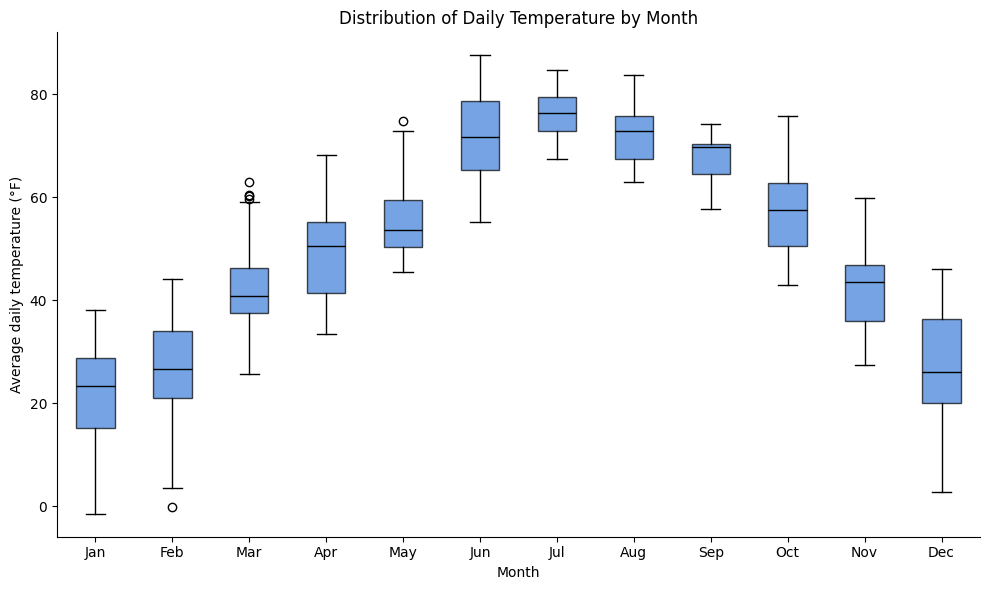

In [10]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
groups = [df.loc[df["month"] == m, "temperature_2m"] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(groups, tick_labels=month_names, patch_artist=True,
           boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
           medianprops=dict(color="black"))

ax.set_xlabel("Month")
ax.set_ylabel("Average daily temperature (°F)")
ax.set_title("Distribution of Daily Temperature by Month")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

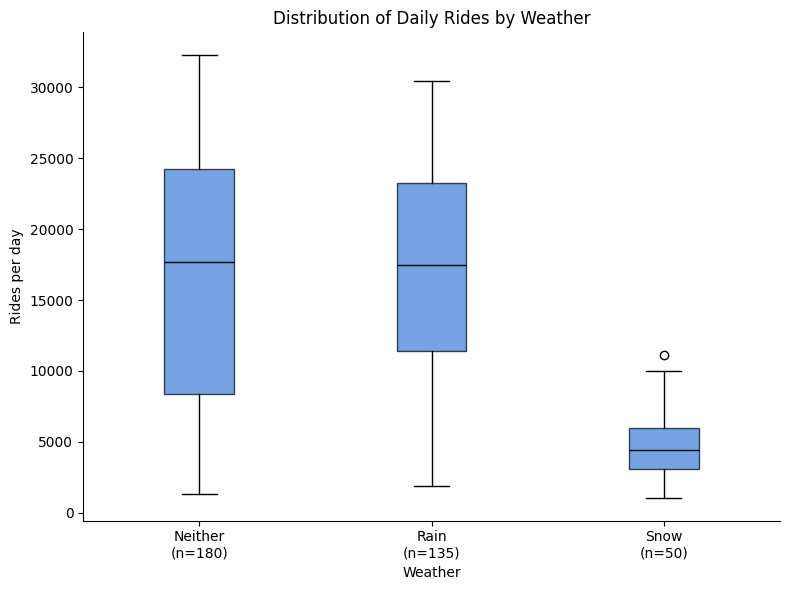

In [11]:
df["weather"] = np.select(
    [df["snowfall"] > 0, df["rain"] > 0],
    ["Snow", "Rain"],
    default="Neither",
)
order = ["Neither", "Rain", "Snow"]
groups = [df.loc[df["weather"] == w, "rides"] for w in order]
labels = [f"{w}\n(n={len(g)})" for w, g in zip(order, groups)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.boxplot(groups, tick_labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#3b7dd8", alpha=0.7),
           medianprops=dict(color="black"))
ax.set_xlabel("Weather")
ax.set_ylabel("Rides per day")
ax.set_title("Distribution of Daily Rides by Weather")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()